In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
from sklearn.tree import plot_tree

In [3]:
df = pd.read_csv("Dataset\\heart.csv")

In [4]:
# Display first five records
print(df.head())

# Dataset information
print(df.info())

# Check missing values
print(df.isnull().sum())

# Check dataset dimensions
print("Dataset Shape:", df.shape)

   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   52    1   0       125   212    0        1      168      0      1.0      2   
1   53    1   0       140   203    1        0      155      1      3.1      0   
2   70    1   0       145   174    0        1      125      1      2.6      0   
3   61    1   0       148   203    0        1      161      0      0.0      2   
4   62    0   0       138   294    1        1      106      0      1.9      1   

   ca  thal  target  
0   2     3       0  
1   0     3       0  
2   0     3       0  
3   1     3       0  
4   3     2       0  
<class 'pandas.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs    

In [5]:
# Independent variables
X = df.drop('target', axis=1)

# Dependent variable
y = df['target']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Distribution:")
print(y.value_counts())

Features Shape: (1025, 13)
Target Shape: (1025,)

Target Distribution:
target
1    526
0    499
Name: count, dtype: int64


In [6]:
# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (820, 13)
Testing Features: (205, 13)
Training Target: (820,)
Testing Target: (205,)


In [7]:
# Create Decision Tree model
dt_model = DecisionTreeClassifier(
    criterion='gini',
    max_depth=None,
    random_state=42
)

# Train the model
dt_model.fit(X_train, y_train)

# Make predictions
y_pred_dt = dt_model.predict(X_test)

print("Decision Tree Model Trained Successfully!")

Decision Tree Model Trained Successfully!


In [8]:
# Calculate training and testing accuracy
train_accuracy = dt_model.score(X_train, y_train)
test_accuracy = accuracy_score(y_test, y_pred_dt)

print("Decision Tree Performance")
print("Training Accuracy:", round(train_accuracy * 100, 2), "%")
print("Testing Accuracy:", round(test_accuracy * 100, 2), "%")

Decision Tree Performance
Training Accuracy: 100.0 %
Testing Accuracy: 98.54 %


In [9]:
# Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt))


Classification Report:
              precision    recall  f1-score   support

           0       0.97      1.00      0.99       100
           1       1.00      0.97      0.99       105

    accuracy                           0.99       205
   macro avg       0.99      0.99      0.99       205
weighted avg       0.99      0.99      0.99       205



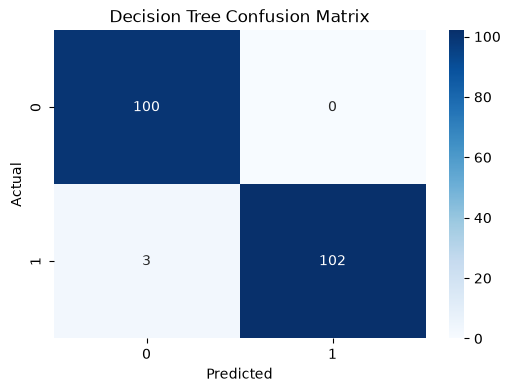

In [15]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_dt)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.savefig("screenshots/decision_tree_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

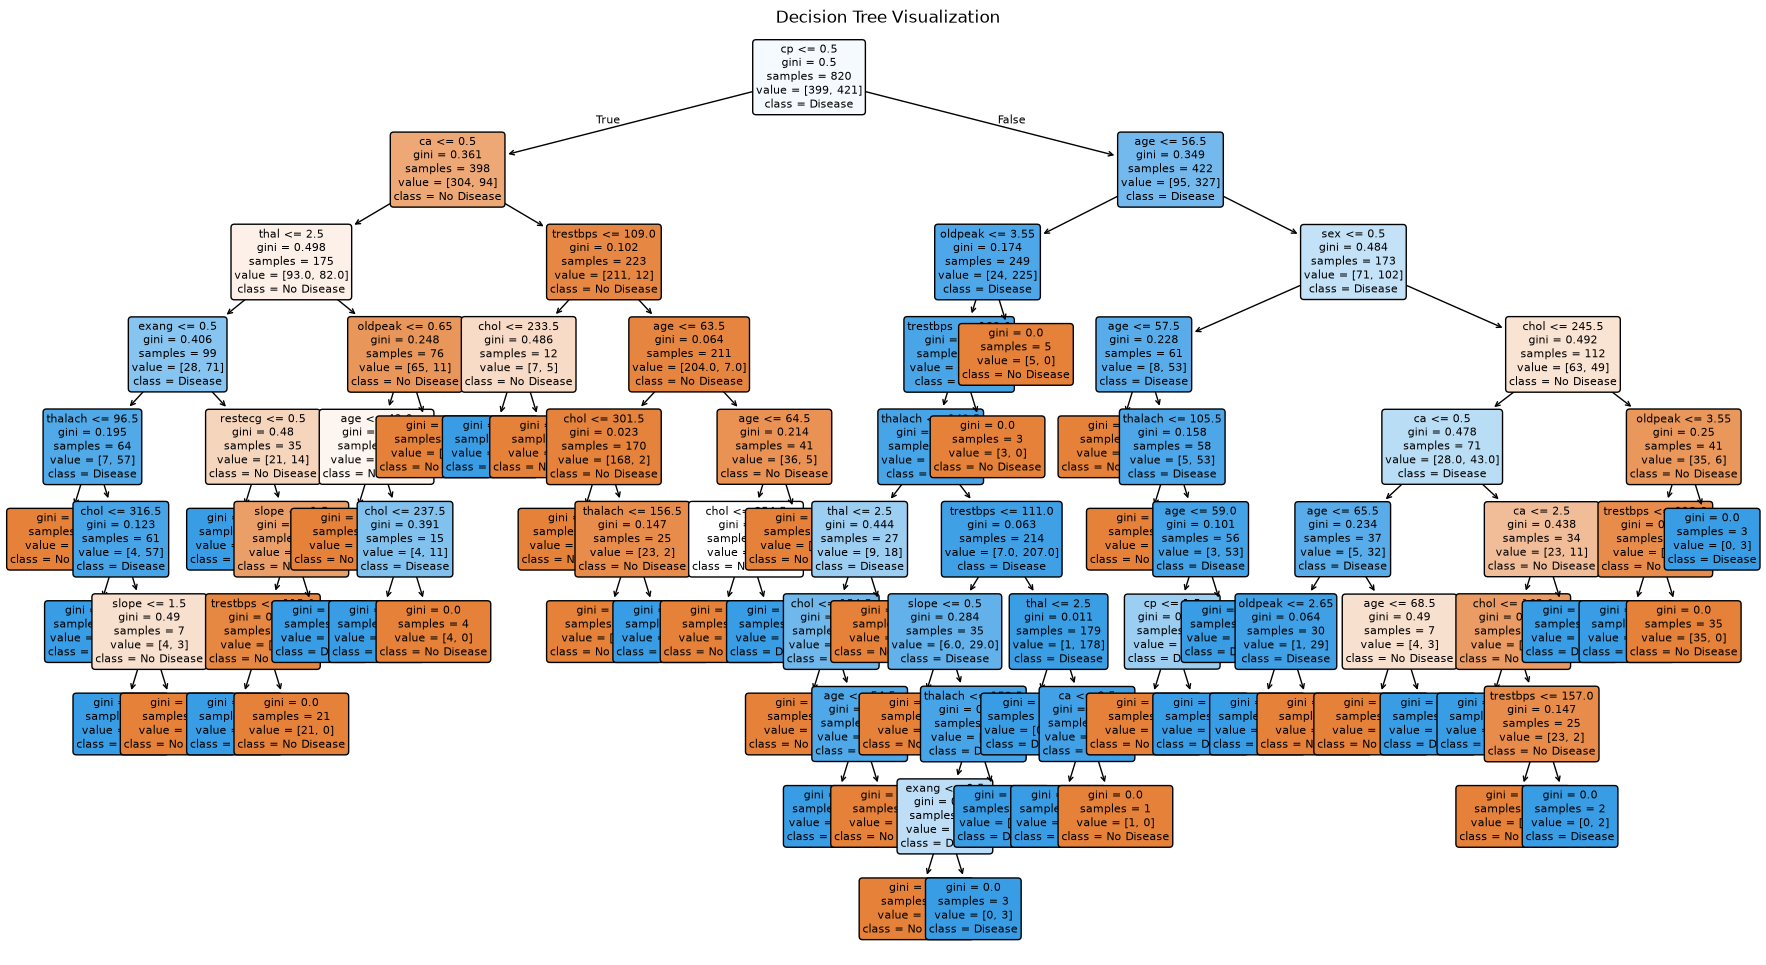

In [14]:
plt.figure(figsize=(22, 12))

plot_tree(
    dt_model,
    feature_names=X.columns,
    class_names=['No Disease', 'Disease'],
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Decision Tree Visualization")
plt.savefig("screenshots/decision_tree.png", dpi=300, bbox_inches="tight")
plt.show()

In [16]:
# Different maximum tree depths
depths = [1, 2, 3, 4, 5, 6, 8, 10, None]

train_scores = []
test_scores = []

for depth in depths:

    model = DecisionTreeClassifier(
        criterion='gini',
        max_depth=depth,
        random_state=42
    )

    model.fit(X_train, y_train)

    train_scores.append(model.score(X_train, y_train))
    test_scores.append(model.score(X_test, y_test))

In [17]:
# Display accuracy comparison
depth_results = pd.DataFrame({
    'Max Depth': [str(d) for d in depths],
    'Training Accuracy': train_scores,
    'Testing Accuracy': test_scores
})

print(depth_results)

  Max Depth  Training Accuracy  Testing Accuracy
0         1           0.769512          0.721951
1         2           0.769512          0.721951
2         3           0.845122          0.853659
3         4           0.885366          0.839024
4         5           0.929268          0.873171
5         6           0.965854          0.921951
6         8           0.997561          0.975610
7        10           1.000000          0.985366
8      None           1.000000          0.985366


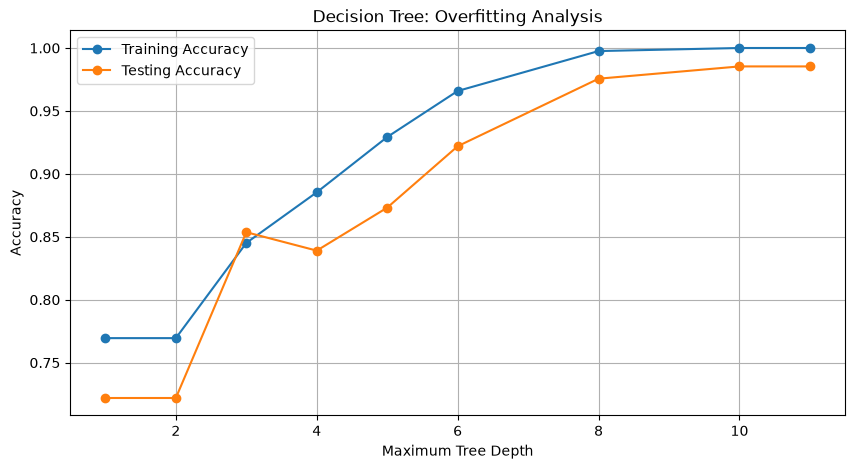

In [18]:
plt.figure(figsize=(10, 5))

plt.plot(depths[:-1] + [11], train_scores,
         marker='o', label='Training Accuracy')

plt.plot(depths[:-1] + [11], test_scores,
         marker='o', label='Testing Accuracy')

plt.xlabel("Maximum Tree Depth")
plt.ylabel("Accuracy")
plt.title("Decision Tree: Overfitting Analysis")
plt.legend()
plt.grid(True)

plt.savefig("screenshots/overfitting_analysis.png", dpi=300, bbox_inches="tight")
plt.show()

In [19]:
# Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    criterion='gini',
    max_depth=None,
    random_state=42
)

# Train the model
rf_model.fit(X_train, y_train)

# Make predictions
y_pred_rf = rf_model.predict(X_test)

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


In [20]:
# Calculate training and testing accuracy
rf_train_accuracy = rf_model.score(X_train, y_train)
rf_test_accuracy = accuracy_score(y_test, y_pred_rf)

print("Random Forest Performance")
print("Training Accuracy:", round(rf_train_accuracy * 100, 2), "%")
print("Testing Accuracy:", round(rf_test_accuracy * 100, 2), "%")

Random Forest Performance
Training Accuracy: 100.0 %
Testing Accuracy: 100.0 %


In [21]:
# Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))


Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       100
           1       1.00      1.00      1.00       105

    accuracy                           1.00       205
   macro avg       1.00      1.00      1.00       205
weighted avg       1.00      1.00      1.00       205



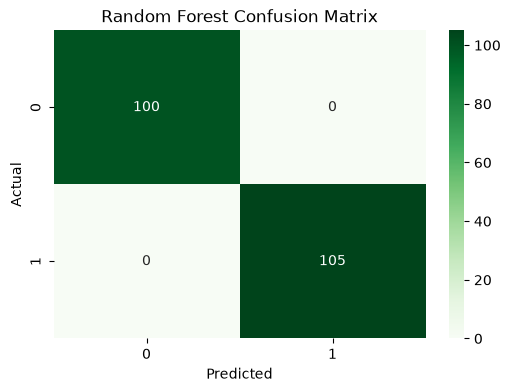

In [22]:
# Confusion Matrix
cm_rf = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(6, 4))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens')

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.savefig("screenshots/random_forest_confusion_matrix.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [23]:
# Create comparison dataframe
comparison = pd.DataFrame({
    'Model': ['Decision Tree', 'Random Forest'],
    'Training Accuracy': [
        train_accuracy * 100,
        rf_train_accuracy * 100
    ],
    'Testing Accuracy': [
        test_accuracy * 100,
        rf_test_accuracy * 100
    ]
})

print(comparison.round(2))

           Model  Training Accuracy  Testing Accuracy
0  Decision Tree              100.0             98.54
1  Random Forest              100.0            100.00


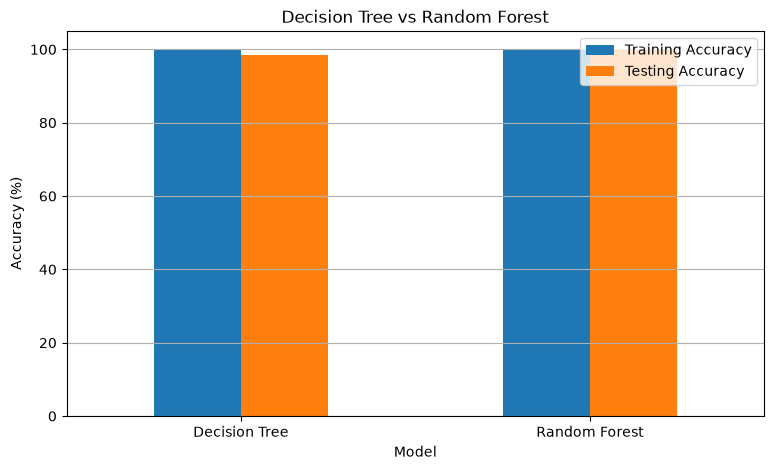

In [24]:
# Visualize model comparison
comparison.set_index('Model').plot(
    kind='bar',
    figsize=(9, 5),
    ylim=(0, 105)
)

plt.title("Decision Tree vs Random Forest")
plt.ylabel("Accuracy (%)")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.legend()
plt.grid(axis='y')

plt.savefig("screenshots/model_comparison.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [25]:
# Extract feature importance
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print("Feature Importance:")
print(feature_importance)

Feature Importance:
     Feature  Importance
2         cp    0.142094
7    thalach    0.117349
11        ca    0.114844
9    oldpeak    0.112634
12      thal    0.095930
0        age    0.091285
4       chol    0.077771
8      exang    0.073707
3   trestbps    0.067765
10     slope    0.048711
1        sex    0.026682
6    restecg    0.020438
5        fbs    0.010790


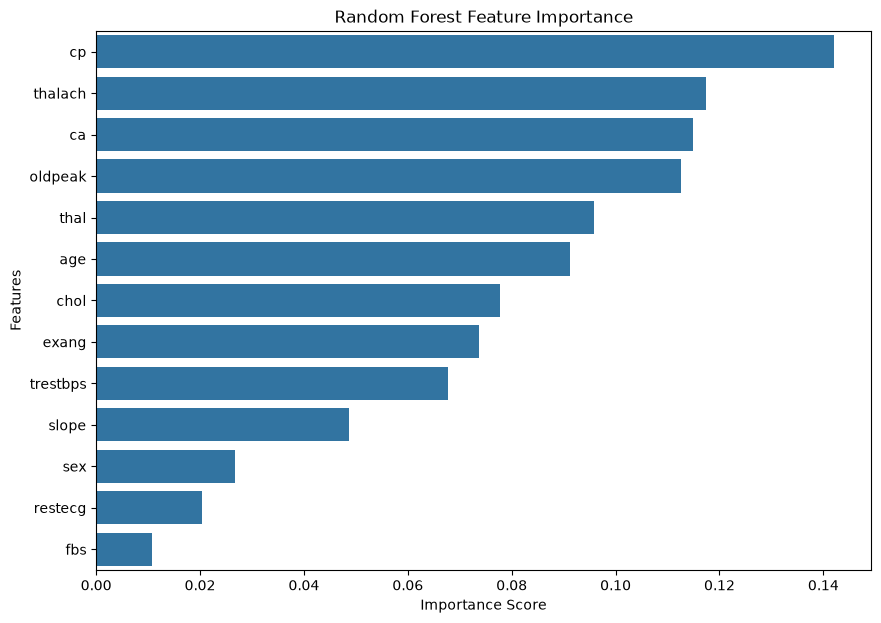

In [26]:
# Visualize feature importance
plt.figure(figsize=(10, 7))

sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature'
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Features")

plt.savefig("screenshots/feature_importance.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [27]:
# Perform 5-fold cross-validation
dt_cv_scores = cross_val_score(
    dt_model, X, y, cv=5, scoring='accuracy'
)

rf_cv_scores = cross_val_score(
    rf_model, X, y, cv=5, scoring='accuracy'
)

In [28]:
# Display results
print("Decision Tree Cross-Validation Scores:")
print(dt_cv_scores)
print("Mean Accuracy:",
      round(dt_cv_scores.mean() * 100, 2), "%")

print("\nRandom Forest Cross-Validation Scores:")
print(rf_cv_scores)
print("Mean Accuracy:",
      round(rf_cv_scores.mean() * 100, 2), "%")

Decision Tree Cross-Validation Scores:
[1. 1. 1. 1. 1.]
Mean Accuracy: 100.0 %

Random Forest Cross-Validation Scores:
[1.         1.         1.         1.         0.98536585]
Mean Accuracy: 99.71 %


In [29]:
# Create final performance summary
final_results = pd.DataFrame({
    'Model': ['Decision Tree', 'Random Forest'],
    'Training Accuracy (%)': [
        train_accuracy * 100,
        rf_train_accuracy * 100
    ],
    'Testing Accuracy (%)': [
        test_accuracy * 100,
        rf_test_accuracy * 100
    ],
    'Cross Validation Accuracy (%)': [
        dt_cv_scores.mean() * 100,
        rf_cv_scores.mean() * 100
    ]
})

print("\nFinal Model Performance Comparison")
print(final_results.round(2).to_string(index=False))


Final Model Performance Comparison
        Model  Training Accuracy (%)  Testing Accuracy (%)  Cross Validation Accuracy (%)
Decision Tree                  100.0                 98.54                         100.00
Random Forest                  100.0                100.00                          99.71


In [30]:
# Identify best model based on cross-validation
best_model = final_results.loc[
    final_results['Cross Validation Accuracy (%)'].idxmax(),
    'Model'
]

print("\nBest Performing Model:", best_model)


Best Performing Model: Decision Tree


In [31]:
# Save model comparison
final_results.to_csv("model_comparison_results.csv", index=False)

# Save feature importance
feature_importance.to_csv("feature_importance.csv", index=False)

print("Results saved successfully!")

Results saved successfully!
